# SEMMA: predicting red wine sensory quality from laboratory assays

This project uses all five SEMMA stages: Sample, Explore, Modify, Model, and Assess. An ordinal quality score is approximated with regression. The business context and batch delivery are documented extensions surrounding SEMMA, rather than additional named SEMMA stages.

Duplicate measurements require particular care. Exact rows are removed, and identical chemistry vectors remain in the same partition and cross-validation fold. This protects the evaluation from memorizing repeated samples. This is a Python implementation of SEMMA. No SAS execution is claimed.

**Colab instructions:** upload this `.ipynb` to Colab, use a Python 3.11+ CPU runtime, and select Runtime → Run all. The source CSV downloads from Kaggle and is checked against the saved SHA-256. If Kaggle blocks automatic download, download the named CSV from the dataset page and upload it into `cmpe_project_runs/02_semma_wine/data/` under the current working directory (or use the exact path printed by the acquisition error). No API key is embedded. Save your executed notebook and download the resulting artifacts before ending the session.

In [1]:
import sys, subprocess, importlib.metadata as package_metadata
if sys.version_info < (3,11):raise RuntimeError("Python 3.11 or newer is required")
required={"numpy":"2.3.5","pandas":"2.2.3","scikit-learn":"1.8.0","matplotlib":"3.10.8","scipy":"1.17.0","joblib":"1.5.3"}
module_names={"numpy":"numpy","pandas":"pandas","scikit-learn":"sklearn","matplotlib":"matplotlib","scipy":"scipy","joblib":"joblib"}
mismatches=[]
for name,version in required.items():
    try:
        if package_metadata.version(name)!=version:mismatches.append(name)
    except package_metadata.PackageNotFoundError:mismatches.append(name)
already_loaded=[name for name in mismatches if module_names[name] in sys.modules]
if mismatches:
    subprocess.check_call([sys.executable,"-m","pip","install","-q",*[f"{name}=={required[name]}" for name in mismatches]])
if already_loaded:
    raise RuntimeError("Dependencies were replaced after import: "+", ".join(already_loaded)+". Restart the runtime, then Run all.")
print("Dependency setup complete. Loaded library versions are checked in the next cell.")

Dependency setup complete. Loaded library versions are checked in the next cell.


## Setup and reproducibility

This section establishes the environment and verifies the exact source file. Dataset changes fail the checksum check so a different version cannot silently change the experiment.

In [2]:
from pathlib import Path
import json, hashlib, urllib.request, zipfile, io, sys, platform
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import joblib
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, GroupShuffleSplit, GroupKFold
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss, confusion_matrix,
    precision_score, recall_score, f1_score, mean_absolute_error, mean_squared_error, r2_score,
    silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score)
from sklearn.inspection import permutation_importance
SEED = 42
# Notebook runs in the current working directory; scripts run beside their source.
ROOT = Path.cwd() / "cmpe_project_runs" / '02_semma_wine'
for folder in ["data", "artifacts", "figures", "deployment"]:
    (ROOT / folder).mkdir(exist_ok=True, parents=True)
plt.rcParams.update({"axes.prop_cycle": plt.cycler(color=["black", "0.45", "0.7"]), "font.size": 10})
def save_json(name, value):
    (ROOT / "artifacts" / name).write_text(json.dumps(value, indent=2, default=str))
def save_table(name, value):
    value.to_csv(ROOT / "artifacts" / name, index=False)
    print(name + "\n" + value.to_string(index=False))
def save_fig(name):
    plt.tight_layout()
    plt.savefig(ROOT / "figures" / name, dpi=140, bbox_inches="tight")
    plt.close()
def interval(y, pred, metric, repeats=2000, require_two_classes=False):
    rng = np.random.default_rng(SEED)
    values = []
    y, pred = np.asarray(y), np.asarray(pred)
    for _ in range(repeats):
        idx = rng.integers(0, len(y), len(y))
        if not require_two_classes or len(np.unique(y[idx])) > 1:
            values.append(metric(y[idx], pred[idx]))
    return np.quantile(values, [.025, .975]).tolist()
versions = {p: metadata.version(p) for p in ["numpy", "pandas", "scikit-learn", "matplotlib", "scipy", "joblib"]}
import scipy, sklearn
loaded_versions = {"numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
                   "matplotlib": matplotlib.__version__, "scipy": scipy.__version__, "joblib": joblib.__version__}
if loaded_versions != versions:
    raise RuntimeError("Loaded modules differ from installed distributions. Restart the runtime.")
save_json("environment.json", {"python": platform.python_version(), "packages": versions,
    "loaded_module_versions": loaded_versions, "seed": SEED})
print("Environment:", versions)



Environment: {'numpy': '2.3.5', 'pandas': '2.2.3', 'scikit-learn': '1.8.0', 'matplotlib': '3.10.8', 'scipy': '1.17.0', 'joblib': '1.5.3'}


## Acquire and verify the source data

This section establishes the environment and verifies the exact source file. Dataset changes fail the checksum check so a different version cannot silently change the experiment.

In [3]:
SOURCE = 'uciml/red-wine-quality-cortez-et-al-2009'
FILENAME = 'winequality-red.csv'
EXPECTED_SHA256 = 'd6a0d9bd24806944818795f22500c46cb6424cbff517aacda36595d3ed9b2daa'
data_path = ROOT / "data" / FILENAME
if not data_path.exists():
    url = "https://www.kaggle.com/api/v1/datasets/download/" + SOURCE
    try:
        with urllib.request.urlopen(url, timeout=90) as response:
            archive = response.read()
        with zipfile.ZipFile(io.BytesIO(archive)) as zipped:
            data_path.write_bytes(zipped.read(FILENAME))
    except Exception as exc:
        raise RuntimeError("Download failed. Download the CSV from https://www.kaggle.com/datasets/" + SOURCE +
                           " and place it in " + str(data_path)) from exc
actual_sha = hashlib.sha256(data_path.read_bytes()).hexdigest()
if actual_sha != EXPECTED_SHA256:
    raise ValueError("Source checksum changed. Review the dataset revision before rerunning.")
raw = pd.read_csv(data_path)
print("Verified source:", SOURCE, "shape:", raw.shape, "SHA256:", actual_sha)
save_json("source_validation.json", {"source": SOURCE, "sha256": actual_sha, "raw_shape": raw.shape})



Verified source: uciml/red-wine-quality-cortez-et-al-2009 shape: (1599, 12) SHA256: d6a0d9bd24806944818795f22500c46cb6424cbff517aacda36595d3ed9b2daa


## Sample: population, duplicates, grouping, and partitions

Keep the full available dataset rather than downsampling. Remove exact duplicate rows before splitting. Group by the predictor vector so identical chemistry cannot appear in separate partitions. Approximate 60/20/20 proportions may vary because groups stay together.

Collapsing equal measurement/label rows is this experiment's weighting policy. The source describes distinct wine samples, so identical rows are not proven duplicate physical wines. Reported metrics describe the collapsed cohort; chemistry grouping controls overlap across partitions.


In [4]:
assert raw.quality.between(0,10).all()
# Modeling policy: collapse identical measurement/label rows, changing their weight.
# Equal rows are not proven duplicate physical wines; results describe this collapsed cohort.
df=raw.drop_duplicates().reset_index(drop=True)
X=df.drop(columns="quality"); y=df.quality
# Identical chemistry vectors must remain together even if their target scores differ.
groups=pd.util.hash_pandas_object(X,index=False).to_numpy()
split=GroupShuffleSplit(n_splits=1,test_size=.4,random_state=SEED)
train_ids,rest_ids=next(split.split(X,y,groups))
split2=GroupShuffleSplit(n_splits=1,test_size=.5,random_state=SEED)
a,b=next(split2.split(X.iloc[rest_ids],y.iloc[rest_ids],groups[rest_ids]))
val_ids,test_ids=rest_ids[a],rest_ids[b]
assert not (set(groups[train_ids])&set(groups[test_ids]) or set(groups[val_ids])&set(groups[test_ids]) or set(groups[train_ids])&set(groups[val_ids]))
quality={"raw_n":len(raw),"exact_duplicates_removed":len(raw)-len(df),"unique_n":len(df),
    "missing":df.isna().sum().to_dict(),"train_n":len(train_ids),"validation_n":len(val_ids),"test_n":len(test_ids),
    "chemistry_groups":len(np.unique(groups)),"group_overlap":0}
save_json("data_quality.json",quality);print(json.dumps(quality))
pd.DataFrame({"clean_row_index":np.r_[train_ids,val_ids,test_ids],"partition":["train"]*len(train_ids)+["validation"]*len(val_ids)+["test"]*len(test_ids)}).to_csv(ROOT/"artifacts/split_manifest.csv",index=False)



{"raw_n": 1599, "exact_duplicates_removed": 240, "unique_n": 1359, "missing": {"fixed acidity": 0, "volatile acidity": 0, "citric acid": 0, "residual sugar": 0, "chlorides": 0, "free sulfur dioxide": 0, "total sulfur dioxide": 0, "density": 0, "pH": 0, "sulphates": 0, "alcohol": 0, "quality": 0}, "train_n": 815, "validation_n": 272, "test_n": 272, "chemistry_groups": 1359, "group_overlap": 0}


## Explore: training distribution, relationships, and unusual measurements

Explore only training rows: quality imbalance, predictor summaries, correlations, and IQR flags. Flags identify unusual measurements to investigate. They do not automatically justify deleting rare wines.

In [5]:
save_table("train_quality_counts.csv",y.iloc[train_ids].value_counts().sort_index().rename_axis("quality").reset_index(name="n"))
save_table("train_descriptives.csv",X.iloc[train_ids].describe().T.reset_index(names="feature"))
corr=df.iloc[train_ids].corr(numeric_only=True)["quality"].drop("quality").sort_values()
save_table("train_correlations.csv",corr.rename_axis("feature").reset_index(name="pearson_r"))
corr.plot.barh(color="0.35",xlabel="Pearson correlation with ordinal quality",title="Training data only")
save_fig("train_correlations.png")
y.iloc[train_ids].value_counts().sort_index().plot.bar(color="0.4",ylabel="Rows",xlabel="Quality score")
save_fig("train_quality_counts.png")
q1=X.iloc[train_ids].quantile(.25);q3=X.iloc[train_ids].quantile(.75);iqr=q3-q1
outliers=((X.iloc[train_ids]<(q1-1.5*iqr))|(X.iloc[train_ids]>(q3+1.5*iqr))).sum()
save_table("training_iqr_flags.csv",outliers.reset_index(name="flagged_rows").rename(columns={"index":"feature"}))
# Outlier flags are retained: unusual chemistry can be legitimate.



train_quality_counts.csv
 quality   n
       3   5
       4  31
       5 361
       6 321
       7  87
       8  10
train_descriptives.csv
             feature  count      mean       std     min      25%     50%     75%       max
       fixed acidity  815.0  8.270675  1.671097 4.60000  7.10000  7.9000  9.1000  15.90000
    volatile acidity  815.0  0.532000  0.191327 0.12000  0.39000  0.5200  0.6450   1.58000
         citric acid  815.0  0.271006  0.195630 0.00000  0.10000  0.2500  0.4200   1.00000
      residual sugar  815.0  2.510920  1.368226 0.90000  1.90000  2.2000  2.6000  15.50000
           chlorides  815.0  0.088106  0.050918 0.01200  0.07000  0.0790  0.0900   0.61100
 free sulfur dioxide  815.0 16.414724 10.698792 1.00000  8.00000 14.0000 23.0000  72.00000
total sulfur dioxide  815.0 48.759509 35.036290 6.00000 23.00000 40.0000 66.0000 289.00000
             density  815.0  0.996677  0.001844 0.99007  0.99556  0.9967  0.9978   1.00315
                  pH  815.0  3.309411  0.1

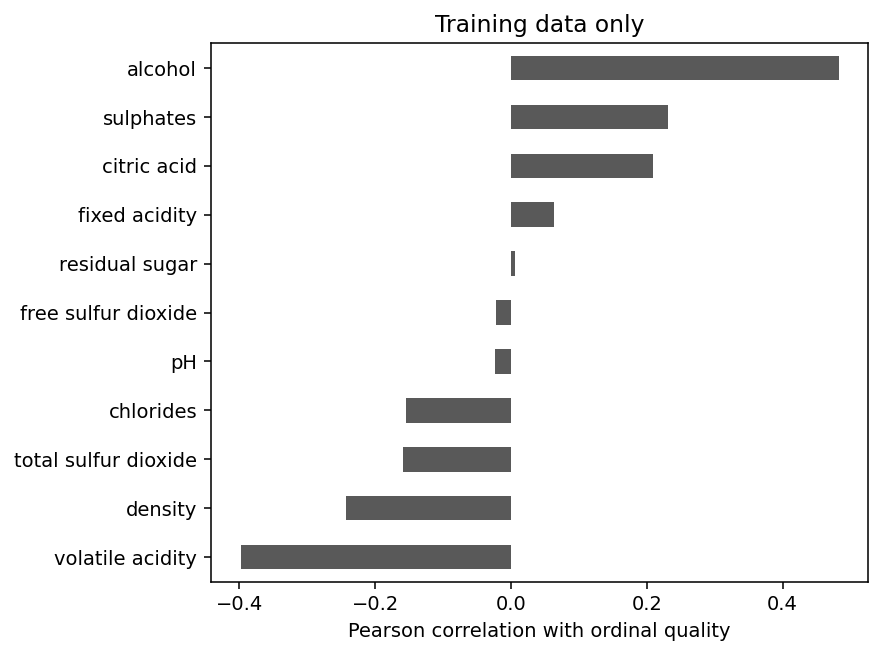

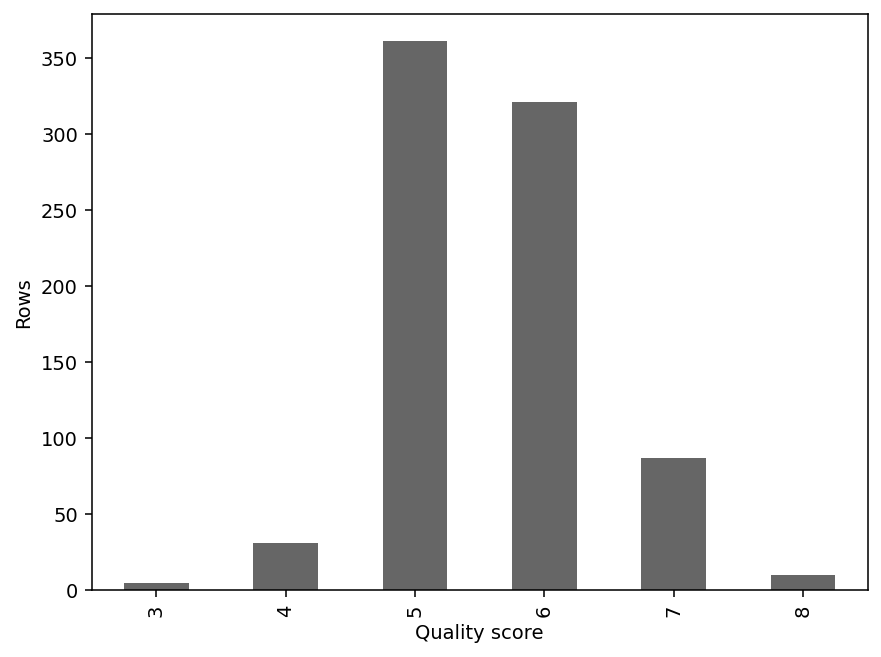

In [6]:
from IPython.display import display, Image
display(Image(filename=str(ROOT / "figures" / 'train_correlations.png')))
display(Image(filename=str(ROOT / "figures" / 'train_quality_counts.png')))

## Modify: train-fold imputation and feature transformation

Select all eleven laboratory inputs and exclude the target. Fold-specific median imputation supports future missing measurements. Standardization supports ridge regression. Trees share the pipeline for a consistent input contract. The sensory target remains ordinal.

In [7]:
# All 11 assays are available at scoring; quality is an ordinal sensory target.
pre=Pipeline([("impute",SimpleImputer(strategy="median")),("scale",StandardScaler())])
save_json("feature_contract.json",{"required_columns":X.columns.tolist(),"target":"quality",
    "target_interpretation":"Ordinal 0-10 sensory score modeled as a regression approximation",
    "duplicates":"Remove exact rows; identical predictors kept within one partition",
    "outliers":"Flag IQR extremes on training data; retain without evidence of measurement error",
    "dictionary":"DATA_DICTIONARY.md","missingness_policy":"Reject all-assay-missing rows; impute partial missingness and expose numeric_missing_count",
    "domain_policy":"Nonnegative concentrations; positive density; pH 0-14; alcohol 0-100. These are conservative demo input guards, not laboratory validation or unit detection."})



## Model: baseline and competing regression families

Compare a median baseline with ridge and random forest regression. GroupKFold keeps chemistry groups intact during hyperparameter search. Negative MAE is a scoring convention, so higher CV scores mean lower error. Freeze the selected model before assessing test rows.

In [8]:
pipe=Pipeline([("prepare",pre),("model",Ridge())])
grid=[{"model":[Ridge()],"model__alpha":[.1,1,10]},
      {"model":[RandomForestRegressor(n_estimators=160,random_state=SEED,n_jobs=1)],
       "model__min_samples_leaf":[2,5],"model__max_depth":[8,None]}]
search=GridSearchCV(pipe,grid,scoring="neg_mean_absolute_error",cv=GroupKFold(3),n_jobs=1)
search.fit(X.iloc[train_ids],y.iloc[train_ids],groups=groups[train_ids])
model=search.best_estimator_
save_table("cv_results.csv",pd.DataFrame(search.cv_results_)[["params","mean_test_score","std_test_score","rank_test_score"]])
baseline=DummyRegressor(strategy="median").fit(X.iloc[train_ids],y.iloc[train_ids])
vp=np.clip(model.predict(X.iloc[val_ids]),0,10)
validation_mae=mean_absolute_error(y.iloc[val_ids],vp)
print("Chosen by training CV:",search.best_params_,"Validation MAE:",validation_mae)



cv_results.csv
                                                                                                                               params  mean_test_score  std_test_score  rank_test_score
                                                                                              {'model': Ridge(), 'model__alpha': 0.1}        -0.506121        0.021163                7
                                                                                                {'model': Ridge(), 'model__alpha': 1}        -0.505968        0.021233                6
                                                                                               {'model': Ridge(), 'model__alpha': 10}        -0.504829        0.021750                5
   {'model': RandomForestRegressor(n_estimators=160, n_jobs=1, random_state=42), 'model__max_depth': 8, 'model__min_samples_leaf': 2}        -0.485726        0.015920                4
   {'model': RandomForestRegressor(n_estimators=160, n_jobs=1, ra

## Assess: holdout errors, uncertainty, and interpretation

Assess absolute error in score points, squared error, explained variance, and the fraction within one point. Break down errors by true score to expose weak evidence at rare extremes. Bootstrap intervals describe conditional holdout uncertainty, not a guarantee for a different region or vintage.

In [9]:
truth=y.iloc[test_ids].to_numpy();pred=np.clip(model.predict(X.iloc[test_ids]),0,10)
base=baseline.predict(X.iloc[test_ids])
metrics={"selected_model":str(search.best_params_),"test_n":len(truth),"validation_MAE":validation_mae,
    "MAE":mean_absolute_error(truth,pred),"baseline_MAE":mean_absolute_error(truth,base),
    "RMSE":float(np.sqrt(mean_squared_error(truth,pred))),"R2":r2_score(truth,pred),
    "within_one_point":float((np.abs(truth-pred)<=1).mean()),"MAE_bootstrap_95pct":interval(truth,pred,mean_absolute_error),
    "retrospective_gate_passed":bool(mean_absolute_error(truth,pred)<mean_absolute_error(truth,base)),
    "bootstrap_repeats":2000,"bootstrap_seed":SEED,"production_approved":False}
save_json("metrics.json",metrics);print(json.dumps(metrics,indent=2))
errors=pd.DataFrame({"quality":truth,"prediction":pred,"absolute_error":np.abs(truth-pred)})
save_table("quality_error_summary.csv",errors.groupby("quality").agg(n=("quality","size"),MAE=("absolute_error","mean")).reset_index())
importance=permutation_importance(model,X.iloc[val_ids],y.iloc[val_ids],scoring="neg_mean_absolute_error",n_repeats=5,random_state=SEED)
save_table("validation_importance.csv",pd.DataFrame({"feature":X.columns,"MAE_increase":importance.importances_mean}).sort_values("MAE_increase",ascending=False))
plt.scatter(truth,pred,color="0.3",alpha=.5,s=15);plt.plot([2,9],[2,9],color="black",linestyle="--")
plt.xlabel("Observed sensory quality");plt.ylabel("Predicted score");save_fig("test_predictions.png")
plt.scatter(pred,truth-pred,color="0.3",s=15);plt.axhline(0,color="black",linestyle="--")
plt.xlabel("Predicted score");plt.ylabel("Observed minus predicted");save_fig("test_residuals.png")



{
  "selected_model": "{'model': RandomForestRegressor(n_estimators=160, n_jobs=1, random_state=42), 'model__max_depth': None, 'model__min_samples_leaf': 2}",
  "test_n": 272,
  "validation_MAE": 0.5009907595850839,
  "MAE": 0.5336887528448879,
  "baseline_MAE": 0.7058823529411765,
  "RMSE": 0.6843015092564279,
  "R2": 0.3879949686380525,
  "within_one_point": 0.8786764705882353,
  "MAE_bootstrap_95pct": [
    0.48167435903397815,
    0.5906628283474848
  ],
  "retrospective_gate_passed": true,
  "bootstrap_repeats": 2000,
  "bootstrap_seed": 42,
  "production_approved": false
}
quality_error_summary.csv
 quality   n      MAE
       3   3 2.008255
       4  14 1.237299
       5 107 0.399682
       6 102 0.419557
       7  44 0.754629
       8   2 1.525967
validation_importance.csv
             feature  MAE_increase
             alcohol      0.125906
           sulphates      0.073667
    volatile acidity      0.018164
total sulfur dioxide      0.010730
                  pH      0.00494

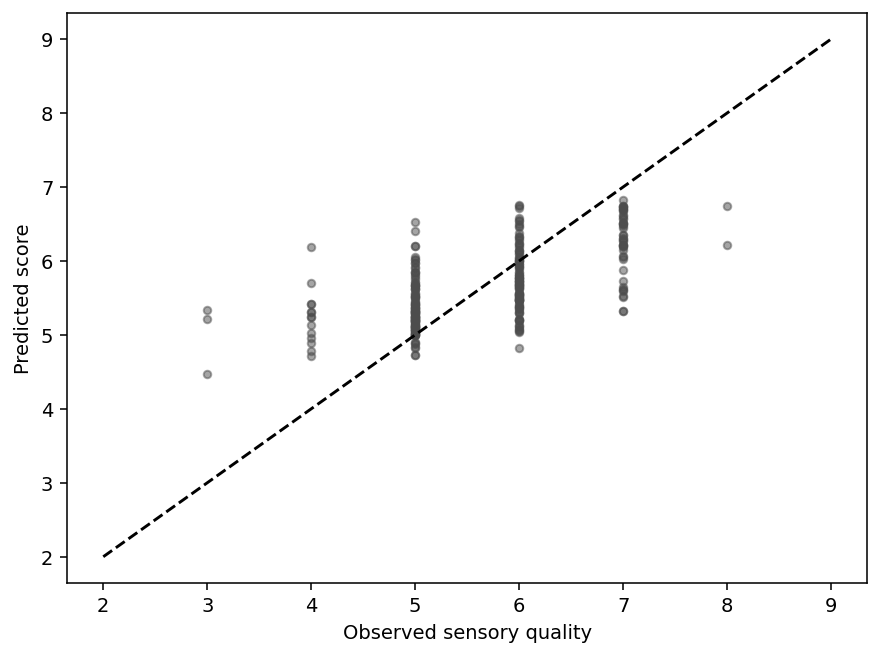

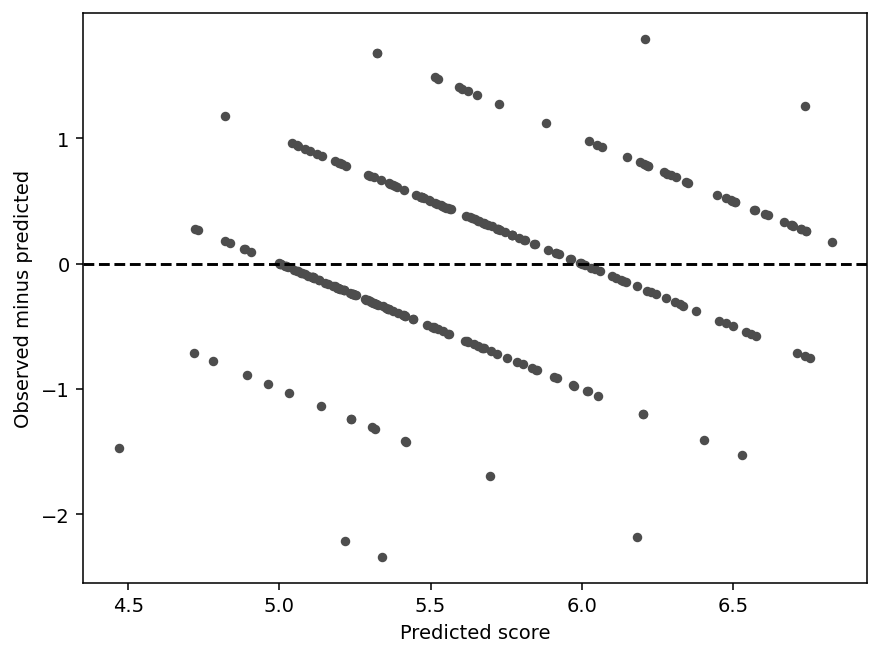

In [10]:
from IPython.display import display, Image
display(Image(filename=str(ROOT / "figures" / 'test_predictions.png')))
display(Image(filename=str(ROOT / "figures" / 'test_residuals.png')))

## Delivery extension: score a batch and verify the saved pipeline

This section establishes the environment and verifies the exact source file. Dataset changes fail the checksum check so a different version cannot silently change the experiment.

In [11]:
joblib.dump({"model":model,"features":X.columns.tolist(),"task":"regression","clip":[0,10]},ROOT/"artifacts/model.joblib")
X.iloc[test_ids].head(5).to_csv(ROOT/"deployment/example_input.csv",index=False)
loaded=joblib.load(ROOT/"artifacts/model.joblib")
np.testing.assert_allclose(np.clip(loaded["model"].predict(X.iloc[test_ids].head(5)),0,10),pred[:5])
save_json("analysis_verification.json",{"chemistry_group_overlap":0,"serialized_predictions_match":True,
    "finite_predictions":bool(np.isfinite(pred).all()),"student_manual_review":"PENDING",
    "colab_runtime_execution":"PENDING; analysis execution does not establish Colab execution"})
print("SEMMA complete. Batch scoring is an additional delivery step beyond the five SEMMA stages.")


SEMMA complete. Batch scoring is an additional delivery step beyond the five SEMMA stages.


## Batch scoring smoke demonstration

The following cell includes the complete scorer, so the notebook works without a repository checkout. It loads the saved pipeline, checks required columns, and scores the example rows. Replace the example CSV with a fresh input after checking the feature contract.

In [12]:
"""Run from any directory: python score.py INPUT.csv OUTPUT.csv."""
from pathlib import Path
import argparse
import csv
import json
import numpy as np
import pandas as pd
import joblib


def select_contact_queue(probability, threshold, capacity_fraction=.30):
    """Apply the frozen threshold, then cap eligible rows by risk and stable input order."""
    probability = np.asarray(probability, dtype=float)
    if not 0 <= capacity_fraction <= 1:
        raise ValueError("capacity_fraction must be within 0-1")
    eligible = np.flatnonzero(probability >= threshold)
    ranked = eligible[np.argsort(-probability[eligible], kind="stable")]
    selected = np.zeros(len(probability), dtype=bool)
    selected[ranked[:int(np.floor(capacity_fraction * len(probability)))]] = True
    return selected


def read_scoring_csv(input_csv):
    """Reject ambiguous headers and ragged records before pandas can infer an index."""
    with open(input_csv, newline="", encoding="utf-8-sig") as handle:
        reader = csv.reader(handle, strict=True)
        try:
            header = next((row for row in reader if row and not (len(row)==1 and not row[0].strip())), None)
            if header is None:
                raise ValueError("CSV has no header")
            if any(not name.strip() for name in header):
                raise ValueError("CSV header names must be nonempty")
            if len(set(header)) != len(header):
                raise ValueError("CSV contains duplicate header names")
            for row in reader:
                if not row or (len(row)==1 and not row[0].strip()):
                    continue
                if len(row) != len(header):
                    raise ValueError(f"CSV record ending at line {reader.line_num} has {len(row)} fields; expected {len(header)}")
        except csv.Error as exc:
            raise ValueError("Malformed CSV structure: " + str(exc)) from exc
    return pd.read_csv(input_csv)


def score(input_csv, output_csv, model_path=None):
    root=ROOT
    bundle=joblib.load(model_path or root/'artifacts/model.joblib')
    data=read_scoring_csv(input_csv)
    missing=set(bundle['features'])-set(data.columns)
    if missing:raise ValueError('Required columns missing: '+', '.join(sorted(missing)))
    data=data[bundle['features']].copy()
    task=bundle['task']
    if task=='classification':
        numeric=['tenure','MonthlyCharges','TotalCharges']
    else:
        numeric=bundle['features']
    for col in numeric:
        normalized=data[col].replace(r'^\s*$',np.nan,regex=True)
        converted=pd.to_numeric(normalized,errors='coerce')
        invalid=normalized.notna() & converted.isna()
        if invalid.any():raise ValueError('Non-numeric values in '+col)
        if np.isinf(converted.dropna()).any():raise ValueError('Infinite values in '+col)
        data[col]=converted
    if len(data)==0:raise ValueError('The input has no rows')
    if task=='classification':
        for col in numeric:
            if data[col].dropna().lt(0).any():raise ValueError('Negative values are invalid in '+col)
        if data['tenure'].dropna().mod(1).ne(0).any():raise ValueError('tenure must contain integer months')
    if task=='regression':
        if data[numeric].isna().all(axis=1).any():raise ValueError('At least one assay is required in every row')
        for col in numeric:
            if data[col].dropna().lt(0).any():raise ValueError('Negative values are invalid in '+col)
        if data['density'].dropna().le(0).any():raise ValueError('density must be positive')
        if not data['pH'].dropna().between(0,14).all():raise ValueError('pH must be within 0-14 for this demo')
        if not data['alcohol'].dropna().between(0,100).all():raise ValueError('alcohol must be within 0-100 percent')
    numeric_missing_count=data[numeric].isna().sum(axis=1).to_numpy()
    model=bundle['model']
    if task=='classification':
        probability=model.predict_proba(data)[:,1]
        threshold=bundle['threshold']
        contact=select_contact_queue(probability,threshold,.30)
        output=pd.DataFrame({'input_row':np.arange(len(data)),'churn_probability':probability,
                             'above_frozen_threshold':probability>=threshold,'contact_queue':contact})
    elif task=='regression':
        output=pd.DataFrame({'input_row':np.arange(len(data)),
                             'predicted_quality':np.clip(model.predict(data),*bundle['clip'])})
    else:
        if data.isna().any().any():raise ValueError('Clustering input requires complete numeric fields')
        if (data['Annual Income (k$)']<=0).any() or not data['Spending Score (1-100)'].between(1,100).all():
            raise ValueError('Income must be positive and spending score must be within 1-100')
        output=pd.DataFrame({'input_row':np.arange(len(data)),'cluster':model.predict(data)})
    output['numeric_missing_count']=numeric_missing_count
    output.to_csv(output_csv,index=False)
    print(output.to_string(index=False))
    return output



score(ROOT / "deployment/example_input.csv", ROOT / "deployment/example_output.csv")


 input_row  predicted_quality  numeric_missing_count
         0           5.298438                      0
         1           5.322969                      0
         2           5.249427                      0
         3           5.252917                      0
         4           5.652753                      0


## Review and submission evidence

Two internal self-review passes are documented in `reviews/INTERNAL_REVISIONS.md`. They are not Claude/GPT-5 critiques. Use `reviews/EXTERNAL_CRITIC_PROMPTS.md` to obtain two genuine external rounds for **each section**, save their responses, implement the corrections, and rerun. Complete `MANUAL_VERIFICATION.md` yourself. This notebook has not been run inside Google Colab or SAS by the assistant. Article and video files are drafts for you to publish and record.

## Export generated artifacts

Each project uses its own working directory. This ZIP includes generated tables, models, figures and scoring outputs; the full reports and source references remain in the assignment package. In Colab the ZIP is downloaded automatically.

In [13]:
import zipfile
export_path=ROOT.parent/(ROOT.name+"_generated_artifacts.zip")
with zipfile.ZipFile(export_path,"w",zipfile.ZIP_DEFLATED) as archive:
    for folder in ["artifacts","figures","deployment"]:
        for item in sorted((ROOT/folder).rglob("*")):
            if item.is_file():archive.write(item,item.relative_to(ROOT))
print("Generated artifact ZIP:",export_path)
try:
    from google.colab import files as colab_files
except ImportError:
    print("Outside Colab: copy the ZIP from the path above.")
else:
    colab_files.download(str(export_path))

Generated artifact ZIP: /workspace/scratch/2f6200312d13/review_work/executions/02_semma_wine/cmpe_project_runs/02_semma_wine_generated_artifacts.zip
Outside Colab: copy the ZIP from the path above.
